# Advertising Budget vs Sales Prediction

## Business Scenario
A consumer goods company promotes its product through:
- Television (TV)
- Radio
- Newspaper

The objective is to understand how advertising spending influences sales and predict future sales from planned advertising budgets.

## Tasks
1. Load and examine the dataset.
2. Use TV, Radio and Newspaper as input features.
3. Use Sales as the target variable.
4. Train a Linear Regression model using historical data.
5. Predict sales for unseen data.
6. Predict sales for TV=150, Radio=20, Newspaper=30.
7. Evaluate prediction error.
8. Interpret model coefficients.
9. Visualize actual vs predicted sales.
10. Provide business and technical recommendations.


In [1]:
# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)


In [ ]:
# 2. Load the dataset
file_path = r"C:\Users\HP\OneDrive\Desktop\calibo\Datasets\Multi linear regression.csv"
df = pd.read_csv(file_path)

# Remove an accidental index column if one exists
df = df.loc[:, ~df.columns.astype(str).str.contains("^Unnamed", case=False, regex=True)]

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
# 3. Examine columns and data types
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nSummary statistics:")
display(df.describe())


Columns:
['TV', 'Radio', 'Newspaper', 'Sales']

Data types:


,Data Type
TV,float64
Radio,float64
Newspaper,float64
Sales,float64



Missing values:


,Missing Values
TV,0
Radio,0
Newspaper,0
Sales,0



Summary statistics:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [4]:
# 4. Select input features and target
features = ["TV", "Radio", "Newspaper"]
target = "Sales"

X = df[features]
y = df[target]

print("Input features:", features)
print("Target:", target)


Input features: ['TV', 'Radio', 'Newspaper']
Target: Sales


## Why these variables?

- **TV:** advertising budget spent on television.
- **Radio:** advertising budget spent on radio.
- **Newspaper:** advertising budget spent on newspapers.
- **Sales:** product sales generated.

The model learns how changes in the three advertising budgets are associated with changes in sales.


In [5]:
# 5. Split historical data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 160
Testing records: 40


In [6]:
# 6. Build and train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed.")
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Advertising Medium": features,
    "Coefficient": model.coef_
})

display(coefficients)


Model training completed.
Intercept: 4.714126402214127


,Advertising Medium,Coefficient
0,TV,0.054509
1,Radio,0.100945
2,Newspaper,0.004337


## Linear Regression Equation

The model has the form:

**Sales = Intercept + (TV coefficient × TV) + (Radio coefficient × Radio) + (Newspaper coefficient × Newspaper)**

A positive coefficient means that, holding the other advertising budgets constant, increasing that medium's spending is associated with higher predicted sales.


In [7]:
# 7. Predict sales for unseen test data
y_pred = model.predict(X_test)

prediction_df = X_test.copy()
prediction_df["Actual Sales"] = y_test.values
prediction_df["Predicted Sales"] = y_pred
prediction_df["Error"] = prediction_df["Actual Sales"] - prediction_df["Predicted Sales"]

display(prediction_df.head(10))


,TV,Radio,Newspaper,Actual Sales,Predicted Sales,Error
95,163.3,31.6,52.9,16.9,17.034772,-0.134772
15,195.4,47.7,52.9,22.4,20.409740,1.990260
30,292.9,28.3,43.2,21.4,23.723989,-2.323989
158,11.7,36.9,45.2,7.3,9.272785,-1.972785
128,220.3,49.0,3.2,24.7,21.682719,3.017281
115,75.1,35.0,52.7,12.6,12.569402,0.030598
69,216.8,43.9,27.2,22.3,21.081195,1.218805
170,50.0,11.6,18.4,8.4,8.690350,-0.290350
174,222.4,3.4,13.1,16.5,17.237013,-0.737013
45,175.1,22.5,31.5,16.1,16.666575,-0.566575


In [8]:
# 8. Evaluate prediction error
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE) : {mae:.4f}")
print(f"Mean Squared Error (MSE)  : {mse:.4f}")
print(f"Root Mean Squared Error   : {rmse:.4f}")
print(f"R-squared (R²)            : {r2:.4f}")


Mean Absolute Error (MAE) : 1.2748
Mean Squared Error (MSE)  : 2.9078
Root Mean Squared Error   : 1.7052
R-squared (R²)            : 0.9059


### Interpretation of error metrics

- **MAE:** average absolute difference between actual and predicted sales.
- **MSE:** average squared prediction error; larger errors receive more penalty.
- **RMSE:** prediction error in approximately the same units as Sales.
- **R²:** proportion of sales variation explained by TV, Radio and Newspaper together.

Lower MAE/RMSE is better, while a higher R² is better.


In [9]:
# 9. Predict sales for the requested advertising budget
new_budget = pd.DataFrame({
    "TV": [150],
    "Radio": [20],
    "Newspaper": [30]
})

predicted_sales = model.predict(new_budget)[0]

print("Advertising Budget:")
display(new_budget)

print(f"Predicted Sales = {predicted_sales:.4f}")


Advertising Budget:


,TV,Radio,Newspaper
0,150,20,30


Predicted Sales = 15.0395


In [10]:
# 10. Interpret coefficients
coef_result = coefficients.copy()
coef_result["Absolute Impact"] = coef_result["Coefficient"].abs()
coef_result = coef_result.sort_values("Absolute Impact", ascending=False)

display(coef_result)

strongest = coef_result.iloc[0]["Advertising Medium"]
least = coef_result.iloc[-1]["Advertising Medium"]

print(f"Strongest impact based on absolute coefficient: {strongest}")
print(f"Least impact based on absolute coefficient: {least}")


,Advertising Medium,Coefficient,Absolute Impact
1,Radio,0.100945,0.100945
0,TV,0.054509,0.054509
2,Newspaper,0.004337,0.004337


Strongest impact based on absolute coefficient: Radio
Least impact based on absolute coefficient: Newspaper


## Important coefficient interpretation

The coefficient represents the expected change in Sales for a **one-unit increase** in that advertising medium, while keeping the other two media budgets constant.

For comparing the coefficients directly, remember that the three variables may have different scales. A more rigorous comparison of relative importance can use standardized features or standardized coefficients.


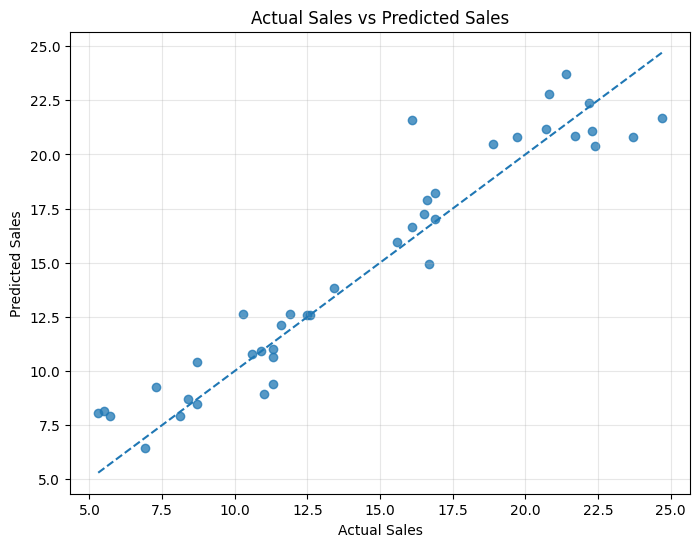

In [11]:
# 11. Visualize Actual Sales vs Predicted Sales
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.75)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")
plt.grid(alpha=0.3)
plt.show()


### Reading the plot

If predictions are accurate, the points should be close to the diagonal reference line.

- Points close to the line → small prediction error.
- Points far from the line → larger prediction error.


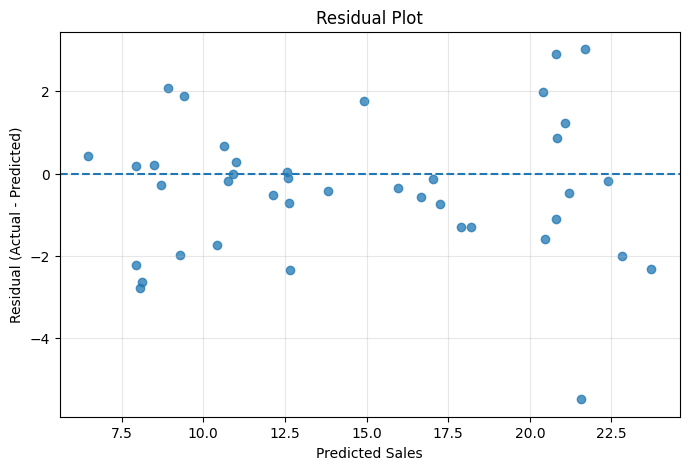

Average residual: -0.398503385030851


In [12]:
# 12. Residual analysis
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()

print("Average residual:", residuals.mean())


## Business Recommendation

**Recommendation:** Allocate more of the advertising budget toward the medium with the strongest positive estimated impact on Sales, while continuously measuring the return from each channel. Avoid increasing spending on a channel solely because its coefficient is positive; confirm that the additional sales justify the additional advertising cost.

## Technical Improvement

**Recommendation:** Compare Linear Regression with stronger models such as Random Forest or Gradient Boosting and use cross-validation. Also test standardized features and interaction/non-linear terms if the relationship between advertising spend and sales is not purely linear.


In [13]:
# 13. Final result summary
summary = pd.DataFrame({
    "Metric": [
        "Training records",
        "Testing records",
        "MAE",
        "MSE",
        "RMSE",
        "R-squared",
        "Requested TV budget",
        "Requested Radio budget",
        "Requested Newspaper budget",
        "Predicted Sales"
    ],
    "Value": [
        len(X_train),
        len(X_test),
        mae,
        mse,
        rmse,
        r2,
        150,
        20,
        30,
        predicted_sales
    ]
})

display(summary.round(4))


,Metric,Value
0,Training records,160.0000
1,Testing records,40.0000
2,MAE,1.2748
3,MSE,2.9078
4,RMSE,1.7052
5,R-squared,0.9059
6,Requested TV budget,150.0000
7,Requested Radio budget,20.0000
8,Requested Newspaper budget,30.0000
9,Predicted Sales,15.0395
